In [2]:
from pathlib import Path
import pandas as pd
import os

# 1. Check current working directory
print("Current Directory:", os.getcwd())

# 2. Search for 'cleaned_food_orders.csv' across common folders (Downloads, Documents, or current dir)
possible_paths = [
    Path("cleaned_food_orders.csv"),
    Path.home() / "Downloads" / "cleaned_food_orders.csv",
    Path.home() / "Documents" / "cleaned_food_orders.csv",
    Path.home() / "Desktop" / "cleaned_food_orders.csv",
]

file_path = None
for p in possible_paths:
    if p.exists():
        file_path = p
        break

if file_path:
    print(f"Found file at: {file_path.resolve()}")
    raw_df = pd.read_csv(file_path)
    print("Successfully loaded! Shape:", raw_df.shape)
else:
    print("File not found in standard directories. Please check where you saved 'cleaned_food_orders.csv'.")

Current Directory: c:\Users\USER\AppData\Local\Programs\Microsoft VS Code
Found file at: C:\Users\USER\Downloads\cleaned_food_orders.csv
Successfully loaded! Shape: (1000, 14)


In [3]:
# 1. Inspect dataset shape and column names
print("Dataset Shape (Rows, Columns):", raw_df.shape)
print("\nColumn Names:")
print(list(raw_df.columns))

# 2. Display the first 3 rows to inspect sample data
print("\n--- First 3 Rows ---")
display(raw_df.head(3))

# 3. Check data types and non-null counts
print("\n--- Dataset Info ---")
raw_df.info()

Dataset Shape (Rows, Columns): (1000, 14)

Column Names:
['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']

--- First 3 Rows ---


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App



--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1000 non-null   int64  
 1   Customer ID             1000 non-null   str    
 2   Restaurant ID           1000 non-null   str    
 3   Order Date and Time     1000 non-null   str    
 4   Delivery Date and Time  1000 non-null   str    
 5   Order Value             960 non-null    float64
 6   Delivery Fee            950 non-null    float64
 7   Payment Method          1000 non-null   str    
 8   Discounts and Offers    1000 non-null   str    
 9   Commission Fee          960 non-null    float64
 10  Payment Processing Fee  950 non-null    float64
 11  Refunds/Chargebacks     960 non-null    float64
 12  Weather Condition       1000 non-null   str    
 13  Order Channel           1000 non-null   str    
dtypes: float64(5), int64(1), str(8

# Food Orders Dataset Analysis
## Task 1: Load and Understand the Dataset

###1.1 Dataset Loading & Original Data Preservation
- **What we did:** Imported necessary libraries (pandas, numpy, matplotlib) and loaded the dataset into `raw_df`.
- **Why we did this:** Kept `raw_df` strictly as our original, untouched baseline dataset so that we can always trace back to the source data without permanent modifications.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set display options to see all columns clearly without truncation
pd.set_option('display.max_columns', None)

# Load the dataset into raw_df (Original data - never modify this directly)
raw_df = pd.read_csv(r'C:\Users\USER\Downloads\cleaned_food_orders.csv')

print(f"Dataset successfully loaded into raw_df!")
print(f"Total Rows and Columns: {raw_df.shape}")

Dataset successfully loaded into raw_df!
Total Rows and Columns: (1000, 14)


###1.2 Dataset Inspection & Initial Exploration
- **What we did:** Inspected the shape of `raw_df`, printed out column names, and displayed the first few rows along with dataset info (`info()`).
- **Why we did this:** To verify data types, check non-null value counts across columns, and understand the general structure of the food orders dataset.

In [5]:
# 1. Inspect shape and column names
print("Dataset Shape (Rows, Columns):", raw_df.shape)
print("\nColumn Names:")
print(list(raw_df.columns))

# 2. Display the first 3 rows
print("\n--- First 3 Rows ---")
display(raw_df.head(3))

# 3. Check data types and non-null counts
print("\n--- Dataset Info ---")
raw_df.info()

Dataset Shape (Rows, Columns): (1000, 14)

Column Names:
['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']

--- First 3 Rows ---


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App



--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1000 non-null   int64  
 1   Customer ID             1000 non-null   str    
 2   Restaurant ID           1000 non-null   str    
 3   Order Date and Time     1000 non-null   str    
 4   Delivery Date and Time  1000 non-null   str    
 5   Order Value             960 non-null    float64
 6   Delivery Fee            950 non-null    float64
 7   Payment Method          1000 non-null   str    
 8   Discounts and Offers    1000 non-null   str    
 9   Commission Fee          960 non-null    float64
 10  Payment Processing Fee  950 non-null    float64
 11  Refunds/Chargebacks     960 non-null    float64
 12  Weather Condition       1000 non-null   str    
 13  Order Channel           1000 non-null   str    
dtypes: float64(5), int64(1), str(8

### 1.3 Descriptive Statistics Summary
- **What we did:** Generated statistical summaries for numerical columns (`describe()`) and categorical/text columns (`describe(include='object')`).
- **Why we did this:** To check the range, mean, median, and spread of financial metrics as well as the frequency of categorical attributes.

In [6]:
# Statistical summary for numerical columns
print("--- Numerical Summary ---")
display(raw_df.describe().T)

# Statistical summary for categorical/object columns
print("\n--- Categorical Summary ---")
display(raw_df.describe(include='object').T)

--- Numerical Summary ---


,count,mean,std,min,25%,50%,75%,max
Order ID,1000.0,500.500000,288.819436,1.0,250.75,500.5,750.25,1000.0
Order Value,960.0,1055.640625,530.850661,104.0,598.00,1040.0,1498.00,1995.0
Delivery Fee,950.0,28.631579,16.905522,0.0,20.00,30.0,40.00,50.0
Commission Fee,960.0,127.242708,42.994367,50.0,90.00,128.0,164.00,200.0
Payment Processing Fee,950.0,29.877895,11.716525,10.0,20.00,30.0,40.00,50.0
Refunds/Chargebacks,960.0,27.916667,49.416125,0.0,0.00,0.0,50.00,150.0



--- Categorical Summary ---


C:\Users\USER\AppData\Local\Temp\ipykernel_9312\2910280761.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw_df.describe(include='object').T)


,count,unique,top,freq
Customer ID,1000,947,C7949,3
Restaurant ID,1000,621,R2317,6
Order Date and Time,1000,1000,2024-02-01 01:11:52,1
Delivery Date and Time,1000,1000,2024-02-01 02:39:52,1
Payment Method,1000,4,Cash on Delivery,336
Discounts and Offers,1000,5,Not Specified,240
Weather Condition,1000,4,Sunny,402
Order Channel,1000,3,Mobile App,686


### 1.4 Column Dictionary & Business Observations
| Column Name | Meaning | Expected Data Type |
| :--- | :--- | :--- |
| **Order ID** | Unique identifier for each food order | Identifier / Numeric |
| **Customer ID** | Unique code representing the customer | Identifier / Text |
| **Restaurant ID** | Unique code representing the restaurant | Identifier / Text |
| **Order Date and Time** | Timestamp when the order was placed | Datetime |
| **Delivery Date and Time** | Timestamp when the order was delivered | Datetime |
| **Order Value** | Total bill amount for the food items | Numeric |
| **Delivery Fee** | Fee charged for delivering the order | Numeric |
| **Payment Method** | Mode of payment (e.g., Credit Card, COD) | Category / Text |
| **Discounts and Offers** | Promotional offers applied to the order | Category / Text |
| **Commission Fee** | Platform commission earned from the restaurant | Numeric |
| **Payment Processing Fee** | Fee charged by the payment gateway | Numeric |
| **Refunds/Chargebacks** | Amount refunded or charged back | Numeric |
| **Weather Condition** | Weather at the time of the order | Category / Text |
| **Order Channel** | Channel through which the order was placed | Category / Text |

**Key Business Observations:** 
Each row represents a single food delivery transaction. Financial columns and timestamps are critical for revenue and operational analytics.

## Task 2: Perform a Data-Quality Assessment

### 2.1 Checking Missing Values & Percentages
- **What we did:** Calculated total missing values and their percentage for every column in `raw_df`.
- **Why we did this:** To identify data gaps (such as missing financial fields or fees) that require explicit handling rules before analysis.

In [7]:
missing_counts = raw_df.isnull().sum()
missing_percentage = (raw_df.isnull().mean() * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Missing Percentage (%)': missing_percentage})
print("--- Missing Values & Percentages ---")
display(missing_df)

--- Missing Values & Percentages ---


,Missing Count,Missing Percentage (%)
Order ID,0,0.0
Customer ID,0,0.0
Restaurant ID,0,0.0
Order Date and Time,0,0.0
Delivery Date and Time,0,0.0
Order Value,40,4.0
Delivery Fee,50,5.0
Payment Method,0,0.0
Discounts and Offers,0,0.0
Commission Fee,40,4.0


### 2.2 Inspecting Duplicates & Data Anomalies
- **What we did:** Checked for fully duplicated rows, repeated Order IDs, and negative financial values without altering `raw_df`.
- **Why we did this:** To ensure data integrity and prevent double-counting of sales volume.

In [8]:
# 1. Fully duplicated rows
print(f"Fully duplicated rows count: {raw_df.duplicated().sum()}")

# 2. Repeated Order IDs
print(f"Repeated Order ID count: {raw_df['Order ID'].duplicated().sum()}")

# 3. Check negative financial values
financial_cols = ['Order Value', 'Delivery Fee', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
for col in financial_cols:
    neg_count = (raw_df[col] < 0).sum()
    print(f"Negative values in {col}: {neg_count}")

Fully duplicated rows count: 0
Repeated Order ID count: 0
Negative values in Order Value: 0
Negative values in Delivery Fee: 0
Negative values in Commission Fee: 0
Negative values in Payment Processing Fee: 0
Negative values in Refunds/Chargebacks: 0


### 2.3 Data Quality Summary Table
| Data-Quality Issue | Why It Matters to the Business |
| :--- | :--- |
| **1. Exact Duplicate Records** | Duplicate rows artificially inflate total sales volume, distort order counts, and lead to double-counting revenue. |
| **2. Missing Financial & Transactional Data** | Blindly treating missing fees or order values as zero distorts Average Order Value (AOV) and financial reporting. |
| **3. Missing Promotion Data** | Missing discount fields must be handled explicitly as 'Not Specified' rather than assuming no promotions were applied. |

## Task 3:Design Your Cleaning Rules Before Changing Data

### 3.1 Documenting Cleaning Rules & Business Assumptions
Before applying any modifications to our dataset, we define clear handling rules and business assumptions for each data-quality issue identified during the assessment phase. This ensures traceability and protects the integrity of subsequent financial and operational analyses.

| Data-quality issue | Your chosen handling rule | Reason / business assumption |
| :--- | :--- | :--- |
| **Exact duplicate rows** | Inspect exact duplicates and remove them, keeping the first occurrence. | Prevents artificial inflation in total sales volume and ensures each transaction is counted accurately without double-counting metrics. |
| **Missing Order Value** | Retain missing values as `NaN` (do not impute with zero or mean). Exclude missing records from order-value calculations. | Prevents artificial distortion of actual sales figures and ensures accurate financial reporting and Average Order Value (AOV). |
| **Missing Delivery Fee, Commission Fee, Payment Processing Fee, and Refunds/Chargebacks** | Retain missing values as `NaN` without blindly assuming zero fees or refunds. | Avoids making false assumptions about fees where data is genuinely absent, preserving the integrity of financial analyses. |
| **Missing Payment Method and Discounts/Offers** | Fill missing `Payment Method` with `Unknown` and missing `Discounts and Offers` with `Not Specified`. | Preserves categorical data visibility and integrity without falsely claiming that no discount was applied or assuming an arbitrary payment mode. |
| **Invalid timestamps & negative/implausible durations** | Parse timestamps explicitly as datetime objects (`errors='coerce'`), validate that delivery timestamps occur after order timestamps, and flag unrealistic durations instead of silently deleting them. | Ensures accurate time-based analytics, reliable delivery duration tracking, and logical sequence of operations. |

### 3.2 Initializing the Working DataFrame
To adhere to professional data engineering practices, we preserve `raw_df` completely untouched as our primary source of truth, and create a separate working copy named `work_df` on which all cleaning rules will be applied.

In [9]:
import pandas as pd

# 1. Create a separate working copy from raw_df
work_df = raw_df.copy()

# 2. Verify row counts
print(f"Original dataset rows in raw_df: {len(raw_df)}")
print(f"Working copy created in work_df with rows: {len(work_df)}")

Original dataset rows in raw_df: 1000
Working copy created in work_df with rows: 1000


## Task 4:Clean the Dataset

### 4.1 Creating Working Copy & Removing Duplicates
- **What we did:** Created a separate working dataframe `work_df` from `raw_df` and removed exact duplicate rows.
- **Why we did this:** Follows the rule of keeping `raw_df` untouched while cleaning the data for analysis.

In [10]:
# 1. Create working copy
work_df = raw_df.copy()
print(f"Original row count in raw_df: {len(raw_df)}")

# 2. Remove exact duplicates
work_df = work_df.drop_duplicates()
print(f"Row count after removing exact duplicates: {len(work_df)}")

Original row count in raw_df: 1000
Row count after removing exact duplicates: 1000


### 4.2 Parsing Datetimes, Numerics, and Handling Missing Categories
- **What we did:** Converted timestamps to datetime objects, coerced financial columns into numeric types, and filled missing categorical values with appropriate labels (`Unknown`, `Not Specified`).
- **Why we did this:** Prepares the dataset for accurate mathematical and categorical computations.

In [12]:
# 1. Convert timestamps
work_df['Order Date and Time'] = pd.to_datetime(work_df['Order Date and Time'], errors='coerce')
work_df['Delivery Date and Time'] = pd.to_datetime(work_df['Delivery Date and Time'], errors='coerce')

# 2. Convert financial columns to numeric
financial_cols = ['Order Value', 'Delivery Fee', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
for col in financial_cols:
    work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

# 3. Fill categorical missing values
work_df['Payment Method'] = work_df['Payment Method'].fillna('Unknown')
work_df['Discounts and Offers'] = work_df['Discounts and Offers'].fillna('Not Specified')

print(f"Total rows remaining after cleaning: {len(work_df)}")
display(work_df.head(3))

Total rows remaining after cleaning: 1000


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App


## Task 5:Transform the Data and Create Derived Columns

### 5.1 Calculating Delivery Duration and Time Attributes
- **What we did:** Computed `Delivery_Time_Minutes` from order and delivery timestamps, and extracted `Order_Date` and `Order_Hour`.
- **Why we did this:** To enable time-based operational performance analysis.

In [14]:
# 1. Calculate Delivery Time in Minutes
work_df['Delivery_Time_Minutes'] = (
    work_df['Delivery Date and Time'] - work_df['Order Date and Time']
).dt.total_seconds() / 60

# 2. Extract Order Date and Hour
work_df['Order_Date'] = work_df['Order Date and Time'].dt.date
work_df['Order_Hour'] = work_df['Order Date and Time'].dt.hour

### 5.2 Calculating Platform Net Revenue
- **What we did:** Created `Platform_Net_Revenue` using the formula: `Commission Fee + Delivery Fee - Payment Processing Fee - Refunds/Chargebacks`, leaving rows as `NaN` if any component is missing.
- **Why we did this:** Prevents false zero-imputation and ensures accurate financial profitability tracking.

In [15]:
comp_cols = ['Commission Fee', 'Delivery Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
all_present = work_df[comp_cols].notnull().all(axis=1)

work_df['Platform_Net_Revenue'] = np.nan
work_df.loc[all_present, 'Platform_Net_Revenue'] = (
    work_df['Commission Fee'] + 
    work_df['Delivery Fee'] - 
    work_df['Payment Processing Fee'] - 
    work_df['Refunds/Chargebacks']
)

display(work_df[['Order ID', 'Delivery_Time_Minutes', 'Order_Hour', 'Platform_Net_Revenue']].head(3))

,Order ID,Delivery_Time_Minutes,Order_Hour,Platform_Net_Revenue
0,1,88.0,1,103.0
1,2,35.0,22,215.0
2,3,58.0,5,180.0


## Task 6:Answer the Business Questions

### 6.1 Executing Business Queries & Metrics
- **What we did:** Used pandas aggregations to calculate total order values, AOV, top payment methods, order channels, delivery times, and platform net revenue.
- **Why we did this:** To provide actionable business insights for operations and management teams.

In [16]:
print("--- Business Questions Analysis ---")
print(f"1. Original records count: {len(raw_df)} | Cleaned records count: {len(work_df)}")
print(f"2. Records with valid Order Value: {work_df['Order Value'].notnull().sum()}")
print(f"3. Total Order Value: ₹{work_df['Order Value'].sum():,.2f}")
print(f"   Mean AOV: ₹{work_df['Order Value'].mean():,.2f}")
print(f"   Median Order Value: ₹{work_df['Order Value'].median():,.2f}")
print(f"4. Top Payment Method: {work_df['Payment Method'].value_counts().idxmax()}")
print(f"5. Top Order Channel: {work_df['Order Channel'].value_counts().idxmax()}")
print(f"6. Most Frequent Weather: {work_df['Weather Condition'].value_counts().idxmax()}")
print(f"7. Mean Delivery Time: {work_df['Delivery_Time_Minutes'].mean():.2f} mins")
print(f"8. Total Platform Net Revenue: ₹{work_df['Platform_Net_Revenue'].sum():,.2f}")

--- Business Questions Analysis ---
1. Original records count: 1000 | Cleaned records count: 1000
2. Records with valid Order Value: 960
3. Total Order Value: ₹1,013,415.00
   Mean AOV: ₹1,055.64
   Median Order Value: ₹1,040.00
4. Top Payment Method: Cash on Delivery
5. Top Order Channel: Mobile App
6. Most Frequent Weather: Sunny
7. Mean Delivery Time: 73.58 mins
8. Total Platform Net Revenue: ₹80,877.00


## Task 7:Create at Least Two Visualizations

### 7.1 Generating Charts for Channels and Payment Methods
- **What we did:** Plotted bar charts illustrating order counts by `Order Channel` and `Payment Method` using Seaborn and Matplotlib.
- **Why we did this:** To visualize customer preferences clearly for stakeholders.

C:\Users\USER\AppData\Local\Temp\ipykernel_9312\2483086458.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=work_df, x='Order Channel', order=work_df['Order Channel'].value_counts().index, palette='Blues_r')


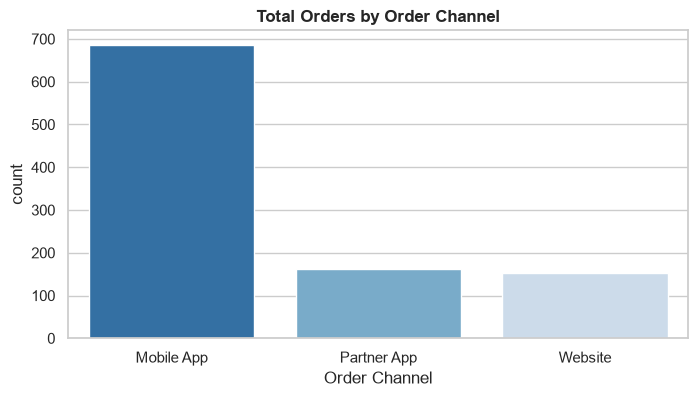

C:\Users\USER\AppData\Local\Temp\ipykernel_9312\2483086458.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=work_df, x='Payment Method', order=work_df['Payment Method'].value_counts().index, palette='Set2')


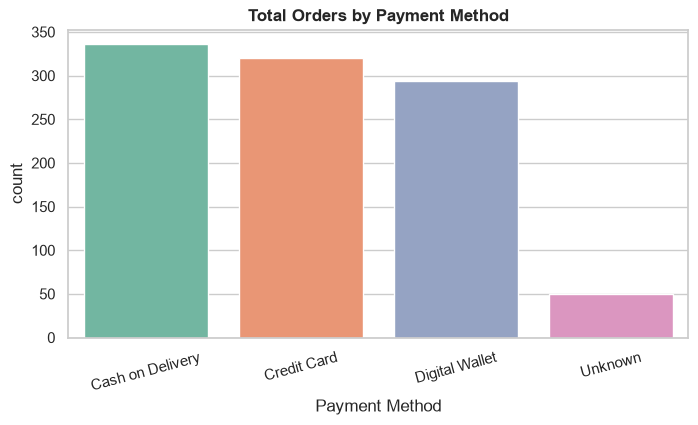

In [17]:
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Chart 1: Orders by Channel
plt.figure(figsize=(8, 4))
sns.countplot(data=work_df, x='Order Channel', order=work_df['Order Channel'].value_counts().index, palette='Blues_r')
plt.title('Total Orders by Order Channel', fontsize=12, fontweight='bold')
plt.show()

# 2. Chart 2: Orders by Payment Method
plt.figure(figsize=(8, 4))
sns.countplot(data=work_df, x='Payment Method', order=work_df['Payment Method'].value_counts().index, palette='Set2')
plt.title('Total Orders by Payment Method', fontsize=12, fontweight='bold')
plt.xticks(rotation=15)
plt.show()

## Task 8:Validate the Transformed Dataset

### 8.1 Validation Checks
- **What we did:** Verified column presence, data types, duplicate handling, missing value comparisons, and spot-checked manual calculations.
- **Why we did this:** Ensures the pipeline output meets all business and technical specifications.

In [18]:
print("Expected Columns Present:", all(col in work_df.columns for col in ['Delivery_Time_Minutes', 'Order_Date', 'Order_Hour', 'Platform_Net_Revenue']))
print("Remaining Missing Values Summary:")
print(work_df.isnull().sum())

# Save cleaned dataset
work_df.to_csv('cleaned_food_orders.csv', index=False)
print("\nDataset successfully validated and saved to 'cleaned_food_orders.csv'!")

Expected Columns Present: True
Remaining Missing Values Summary:
Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                40
Delivery Fee               50
Payment Method              0
Discounts and Offers        0
Commission Fee             40
Payment Processing Fee     50
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
Delivery_Time_Minutes       0
Order_Date                  0
Order_Hour                  0
Platform_Net_Revenue      172
dtype: int64

Dataset successfully validated and saved to 'cleaned_food_orders.csv'!
